#Câu a Nhập dữ liệu đầu vào, tiền xử lý và đổi tên các cột dữ liệu

In [ ]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# 1. Nhập dữ liệu đầu vào
data_path = 'heart.csv'  

# Danh sách 14 tên cột chuẩn theo yêu cầu đề bài
columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure',
    'cholesterol', 'fasting_blood_sugar', 'rest_ecg',
    'max_heart_rate_achieved', 'exercise_induced_angina',
    'st_depression', 'st_slope', 'num_major_vessels',
    'thalassemia', 'target'
]

# Đọc dữ liệu (tự động nhận diện trường hợp file có header hoặc không header, xử lý '?' thành NaN)
try:
    df_preview = pd.read_csv(data_path, nrows=5, na_values=['?', ' ', 'NA'])
    if all(str(c).replace('.', '').isdigit() for c in df_preview.columns):
        data = pd.read_csv(data_path, names=columns, na_values=['?', ' ', 'NA'])
    else:
        data = pd.read_csv(data_path, na_values=['?', ' ', 'NA'])
        if len(data.columns) == 14:
            data.columns = columns
except Exception as e:
    data = pd.read_csv(data_path, names=columns, na_values=['?', ' ', 'NA'])

print(f"Số lượng dữ liệu ban đầu: {len(data)}")

# Tiền xử lý xóa các dòng dữ liệu trống (missing data)
data = data.dropna().reset_index(drop=True)
print(f"Số lượng dữ liệu sau khi xóa dòng trống: {len(data)}")

# Chuyển đổi các cột sang dạng số
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data = data.dropna().reset_index(drop=True)

# Chuẩn hóa nhãn target: 0 là không có bệnh, >=1 là có bệnh (theo chuẩn UCI Cleveland đưa về nhị phân 0 và 1)
data['target'] = data['target'].apply(lambda x: 1 if int(x) > 0 else 0).astype(int)

# Hiển thị thông tin dữ liệu
display(data.head())
data.info()


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Số lượng dữ liệu ban đầu: 303
Số lượng dữ liệu sau khi xóa dòng trống: 303


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    int64  
 13  target                   303 non-null    int64  
dtypes: float64(1), int64(13)
m

#Câu 3 Khảo sát độ tương đồng Pearson bằng đồ thị Heatmap

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


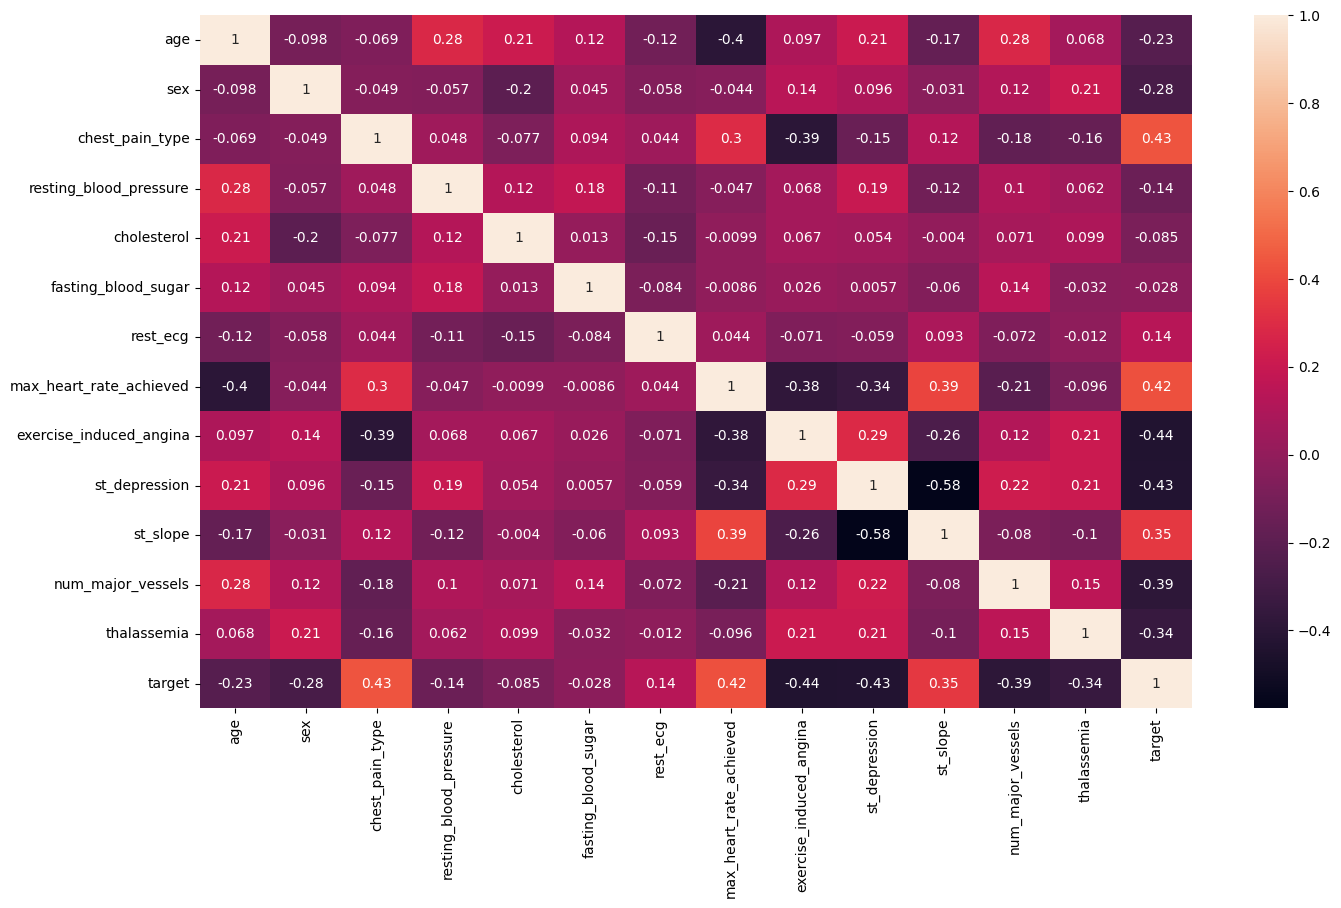

In [16]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson'), annot=True)
plt.show()


#Câu 4 Tách features và labels

In [17]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 4. Tách thuộc tính đặc trưng và thuộc tính quyết định 'target'
features = data.drop('target', axis=1)
labels = data['target']

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels: {labels.shape}")


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước features: (303, 13)
Kích thước labels: (303,)


#Câu 5 Chuyển đổi các cột phân loại về dạng One-Hot Vector

In [18]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Xác định các thuộc tính không phải dạng số trong biến features
cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("features.select_dtypes(exclude=['int64', 'float64']).columns:")
print(cat_cols)

# Chuyển đổi về dạng one-hot vector (nếu có cột object)
features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
display(features_onehot)


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
features.select_dtypes(exclude=['int64', 'float64']).columns:
Index([], dtype='object')


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


#Câu 6 Tách lại dữ liệu Train và Test như ban đầu

In [19]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Sử dụng câu lệnh chia tỷ lệ 70% huấn luyện và 30% kiểm thử theo chuẩn
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print(f"Kích thước Train: {X_train.shape}, {y_train.shape}")
print(f"Kích thước Test: {X_test.shape}, {y_test.shape}")


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước tập Train: (212, 13), (212,)
Kích thước tập Test: (91, 13), (91,)


#Câu 7 Xây dựng cây quyết định ID3 (Entropy) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



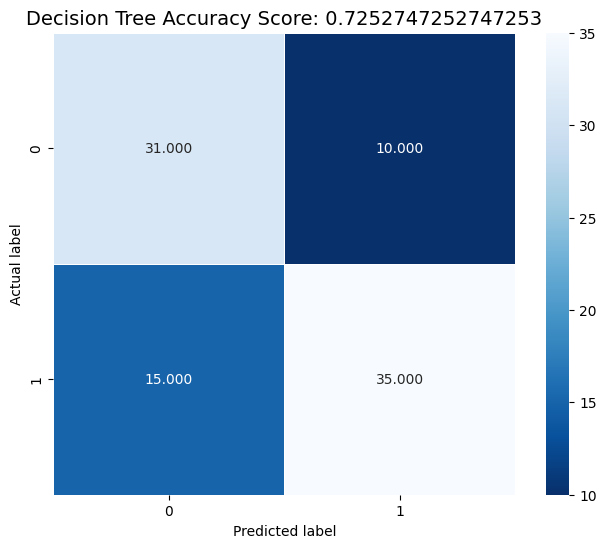

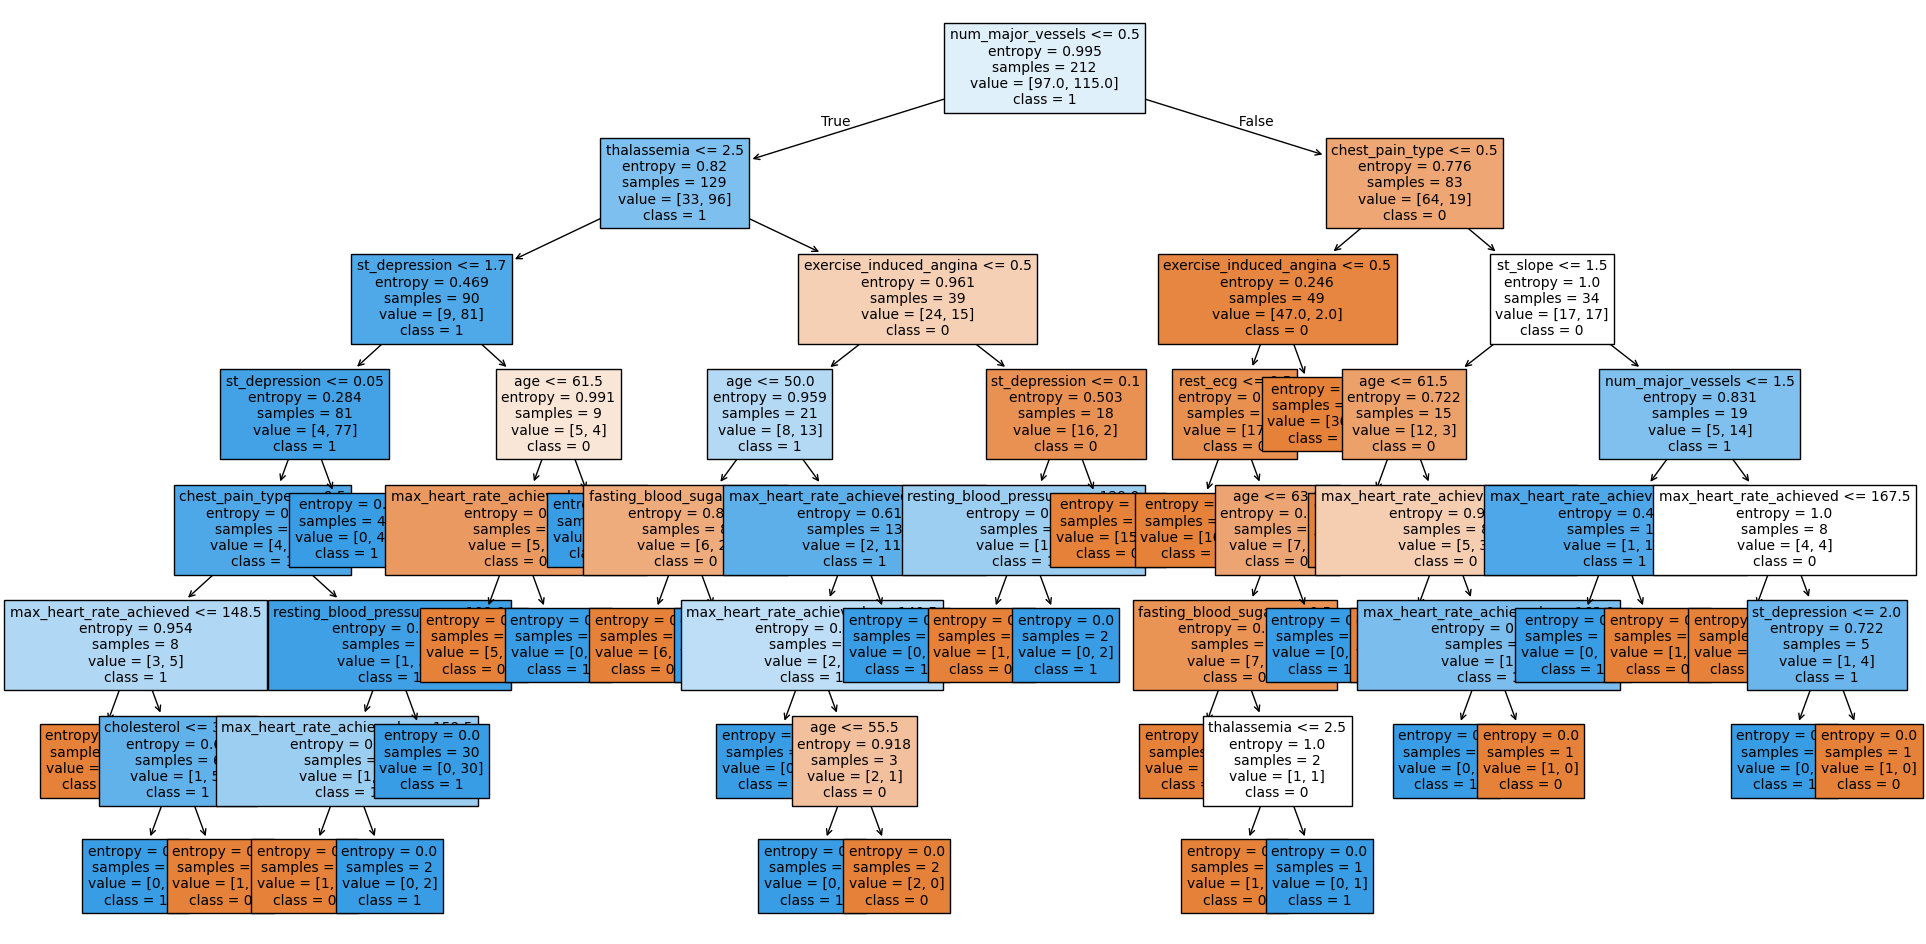

In [20]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn import tree, metrics

# 1. Huấn luyện cây ID3 (criterion="entropy")
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

# 2. Đánh giá mô hình trên tập kiểm thử
tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# 3. Tính toán ma trận nhầm lẫn và vẽ heatmap
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree Accuracy Score: {tree_score}', size=14)
plt.show()

# 4. Biểu diễn cây ID3 và lưu ra file ảnh
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf, filled=True, fontsize=10, feature_names=list(features_onehot.columns), class_names=["0", "1"])
plt.savefig('decision_tree_heart.png', dpi=100)
plt.show()


#Câu 8 Xây dựng cây quyết định CART (Gini) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (CART): 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



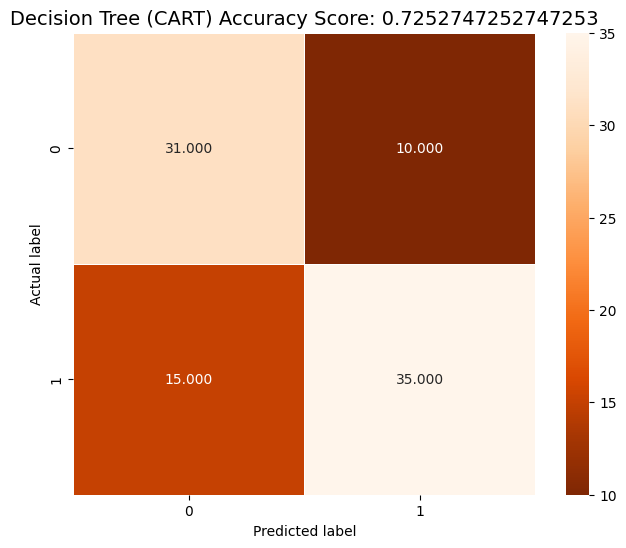

In [21]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 8. Xây dựng cây CART (criterion='gini')
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Đánh giá kết quả
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Oranges_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Accuracy Score: {cart_score}', size=14)
plt.show()


#Câu 9 Xây dựng mô hình Naïve Bayes (GaussianNB) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (Naïve Bayes): 0.8351648351648352
Report:
               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



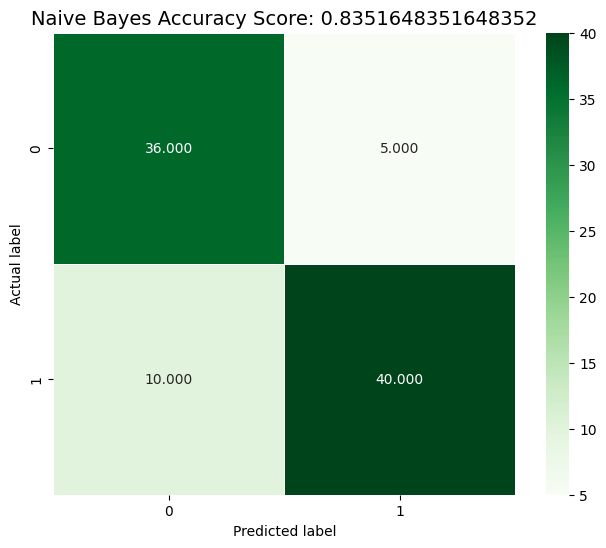

In [22]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 9. Huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

# Ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score}', size=14)
plt.show()


#Câu 10 So sánh kết quả của các mô hình

In [23]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 10. Tổng hợp và so sánh kết quả các mô hình (với nhãn dương là 1 - Có bệnh tim)
comparison_df = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3)', 'Decision Tree (CART)', 'Naïve Bayes'],
    'Accuracy': [tree_score, cart_score, bayes_score],
    'Precision (Target=1)': [
        metrics.precision_score(y_test, tree_pred, pos_label=1),
        metrics.precision_score(y_test, cart_pred, pos_label=1),
        metrics.precision_score(y_test, bayes_pred, pos_label=1)
    ],
    'Recall (Target=1)': [
        metrics.recall_score(y_test, tree_pred, pos_label=1),
        metrics.recall_score(y_test, cart_pred, pos_label=1),
        metrics.recall_score(y_test, bayes_pred, pos_label=1)
    ],
    'F1-score (Target=1)': [
        metrics.f1_score(y_test, tree_pred, pos_label=1),
        metrics.f1_score(y_test, cart_pred, pos_label=1),
        metrics.f1_score(y_test, bayes_pred, pos_label=1)
    ]
})

print("--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---")
display(comparison_df)


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---


,Mô hình,Accuracy,Precision (Target=1),Recall (Target=1),F1-score (Target=1)
0,Decision Tree (ID3),0.725275,0.777778,0.7,0.736842
1,Decision Tree (CART),0.725275,0.777778,0.7,0.736842
2,Naïve Bayes,0.835165,0.888889,0.8,0.842105
